In [ ]:
import sys

sys.path.append("..")  # Add parent directory to sys.path to import utils

from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from utils.io import load_track

plt.style.use("ggplot")

In [5]:
def get_segment_lengths(track_df: pd.DataFrame) -> np.ndarray:
    track_points = track_df[["x_centreline", "y_centreline"]].to_numpy()

    segment_lengths = np.linalg.norm(
        np.diff(track_points, axis=0, append=[track_points[0]]), axis=1
    )

    return segment_lengths

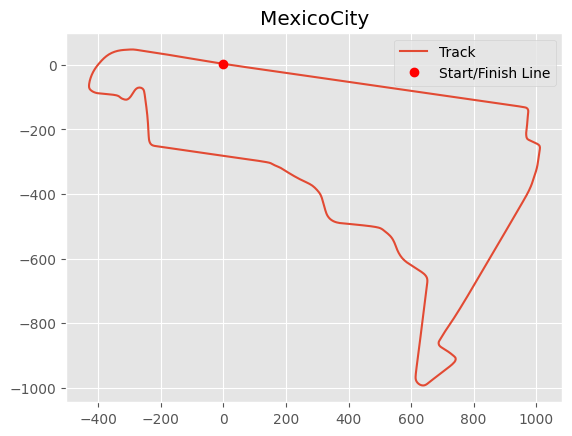

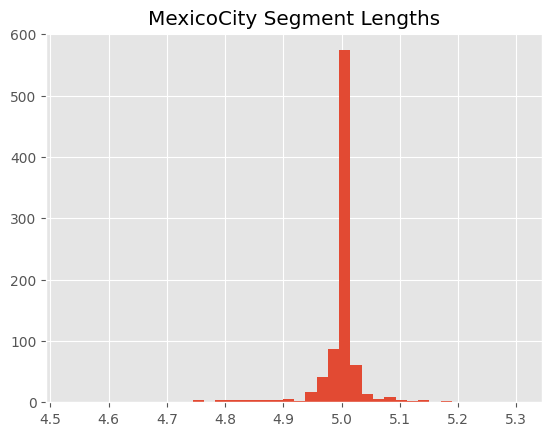

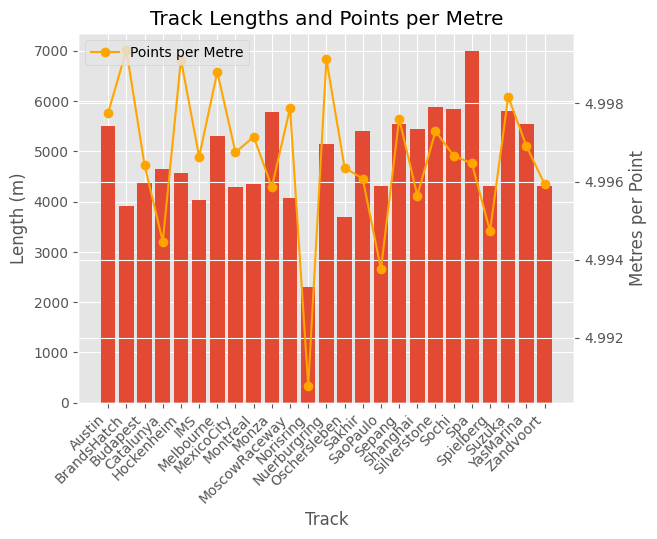

In [ ]:
tracks_dir = Path("../data/tracks")
track_files = list(tracks_dir.glob("*.csv"))

track_names = []
track_lengths = []
mpps = []  # points per meter list

for track_file in track_files:
    track_df = load_track(str(track_file))
    segment_lengths = get_segment_lengths(track_df)
    track_length = np.sum(segment_lengths)
    metres_per_point = track_length / len(track_df)

    track_names.append(track_file.stem)
    track_lengths.append(track_length)
    mpps.append(metres_per_point)

    if track_file.stem == "MexicoCity":
        # Draw the track layout
        plt.plot(track_df["x_centreline"], track_df["y_centreline"], label="Track")
        plt.plot(
            track_df["x_centreline"].iloc[0],
            track_df["y_centreline"].iloc[0],
            "ro",
            label="Start/Finish Line",
        )  # Mark the start/finish line
        plt.title(track_file.stem)
        plt.legend()
        plt.show()

        # Plot histogram of segment lengths
        plt.hist(segment_lengths, bins=40)
        plt.title(f"{track_file.stem} Segment Lengths")
        plt.show()
        # The segments are all around 5m long, so resampling isn't required
        # Also, linear interpolation is sufficient for the track angles

# Draw bar chart of track lengths and points per meter
plt.bar(track_names, track_lengths, label="Track Length (m)")
plt.xlabel("Track")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Length (m)")

plt.twinx()
plt.plot(track_names, mpps, color="orange", marker="o", label="Points per Metre")
plt.ylabel("Metres per Point")
plt.title("Track Lengths and Points per Metre")
plt.legend(loc="upper left")
plt.show()